# RetainIQ 03 - Predict
PREDICTIVE. Metrics come only from the untouched 20% real hold-out.

In [1]:
import sys, json, pandas as pd
sys.path.insert(0, '../src')
from IPython.display import Image, display, Markdown
pd.set_option('display.width', 200)

In [2]:
import train
train.main()

[14:36:14] split train=8000 holdout=2000


[14:36:31] variant A_full done


[14:36:47] variant B_no_inactivity done


[14:37:02] variant C_early_warning done


[14:37:02] chosen per variant: {'A_full': ('logreg', {'C': 0.1}), 'B_no_inactivity': ('logreg', {'C': 0.1}), 'C_early_warning': ('logreg', {'C': 1.0})}


[14:37:02] leakage: A=0.845 B=0.821 C=0.812


... (3 outputs left out)

[14:37:16] stability roc 0.808+-0.010


[14:37:16] stress tests done


[14:37:22] augmentation ablation done


[PASS] no ID overlap train/hold-out
[PASS] no id/target/protected attrs in features (A_full)
[PASS] no id/target/protected attrs in features (B_no_inactivity)
[PASS] no id/target/protected attrs in features (C_early_warning)
[PASS] synthetic parents only from training split
[PASS] no synthetic rows in hold-out
[14:37:24] saved metrics.json and retainiq_model.pkl


In [3]:
M = json.load(open('../outputs/metrics.json'))
pd.read_csv('../outputs/cv_model_comparison.csv').round(4)

,roc_mean,roc_sd,pr_mean,pr_sd,pr_se,brier,variant,model,params
0,0.8262,0.0137,0.5183,0.0176,0.0056,0.1021,A_full,logreg,"{""C"": 0.1}"
1,0.8260,0.0138,0.5183,0.0174,0.0055,0.1021,A_full,logreg,"{""C"": 1.0}"
2,0.7552,0.0177,0.3616,0.0219,0.0069,0.1138,A_full,tree,"{""max_depth"": 3}"
3,0.7801,0.0158,0.4017,0.0176,0.0056,0.1117,A_full,tree,"{""max_depth"": 5}"
4,0.8146,0.0150,0.4919,0.0210,0.0066,0.1048,A_full,random_forest,"{""min_samples_leaf"": 10}"
5,0.8148,0.0153,0.4886,0.0225,0.0071,0.1056,A_full,random_forest,"{""min_samples_leaf"": 30}"
6,0.8213,0.0150,0.5062,0.0193,0.0061,0.1034,A_full,lightgbm,"{""num_leaves"": 7, ""n_estimators"": 400}"
7,0.8174,0.0140,0.4972,0.0184,0.0058,0.1044,A_full,lightgbm,"{""num_leaves"": 15, ""n_estimators"": 300}"
8,0.5000,0.0000,0.1578,0.0003,0.0001,0.1329,A_full,dummy,{}
9,0.8052,0.0157,0.4699,0.0253,0.0080,0.1071,B_no_inactivity,logreg,"{""C"": 0.1}"


In [4]:
pd.DataFrame({k: {m: v[m] for m in ('roc_auc','pr_auc','recall_top10','balance_capture_top10')} for k, v in M['leakage_experiment_holdout'].items()}).round(3)

,rule_of_thumb,A_full,B_no_inactivity,C_early_warning
roc_auc,0.663,0.845,0.821,0.812
pr_auc,0.293,0.564,0.499,0.481
recall_top10,0.234,0.396,0.348,0.335
balance_capture_top10,0.349,0.206,0.198,0.178


In [5]:
pd.DataFrame(M['holdout_metrics']).T.round(3)

,value,ci_low,ci_high
roc_auc,0.821,0.796,0.843
pr_auc,0.499,0.444,0.554
brier,0.104,0.096,0.114
log_loss,0.339,0.315,0.366
recall_top5,0.218,0.187,0.246
precision_top5,0.690,0.590,0.780
lift_top5,4.367,3.732,4.922
balance_capture_top5,0.113,0.069,0.175
recall_top10,0.345,0.306,0.386
precision_top10,0.545,0.475,0.620


In [6]:
pd.read_csv('../outputs/imbalance_comparison.csv').round(4)

,roc_mean,roc_sd,pr_mean,pr_sd,pr_se,brier,model,handling
0,0.8052,0.0157,0.4699,0.0253,0.0080,0.1071,logreg,none
1,0.8048,0.0156,0.4696,0.0250,0.0079,0.1808,logreg,class_weight
2,0.8036,0.0157,0.4682,0.0247,0.0078,0.1805,logreg,smote
3,0.7981,0.0169,0.4600,0.0287,0.0091,0.1084,lightgbm,none
4,0.7979,0.0181,0.4597,0.0289,0.0091,0.1715,lightgbm,class_weight
5,0.7996,0.0177,0.4620,0.0285,0.0090,0.1099,lightgbm,smote


In [7]:
pd.read_csv('../outputs/fairness_audit.csv').round(3)

,attribute,group,n,churn_rate,mean_pred,flag_rate,auc,recall,fpr,n_churners,auc_gap_flag,recall_gap_flag
0,customer_segment,Affluent,291,0.048,0.049,0.021,0.761,0.143,0.014,14,True,False
1,customer_segment,Mass Affluent,539,0.119,0.127,0.148,0.780,0.422,0.112,64,False,True
2,customer_segment,Mass Market,1066,0.220,0.223,0.421,0.797,0.779,0.320,235,False,True
3,customer_segment,Private Banking,104,0.029,0.034,0.010,NaN,0.000,0.010,3,False,False
4,region,East,394,0.173,0.166,0.274,0.790,0.603,0.206,68,False,False
5,region,Metro,439,0.144,0.156,0.237,0.878,0.698,0.160,63,True,False
6,region,North,424,0.146,0.145,0.236,0.792,0.645,0.166,62,False,False
7,region,South,380,0.155,0.177,0.321,0.847,0.814,0.231,59,False,True
8,region,West,363,0.176,0.167,0.281,0.788,0.609,0.211,64,False,False
9,gender,Female,981,0.155,0.167,0.284,0.811,0.684,0.211,152,False,False


In [8]:
M['stress_tests'], M['psi_max'], M['augmentation']['validation']['real_vs_synthetic_auc']

({'baseline': 0.8206462912294417,
  'drop_top_feature(single_product)': 0.7907521272437535,
  '5pct_multiplicative_noise': 0.8192632069515019,
  '10pct_cells_missing': 0.8074243062028322,
  'base_rate_8%': {'auc': 0.823276282823024,
   'mean_pred': 0.1468785839121878,
   'actual': 0.07978142076502732},
  'base_rate_30%': {'auc': 0.828848491637044,
   'mean_pred': 0.19229116859172013,
   'actual': 0.2997920997920998},
  'out_of_range_values_raw_model(no_cleaning)': 0.8136162392134461},
 0.0064,
 0.5521410937500001)

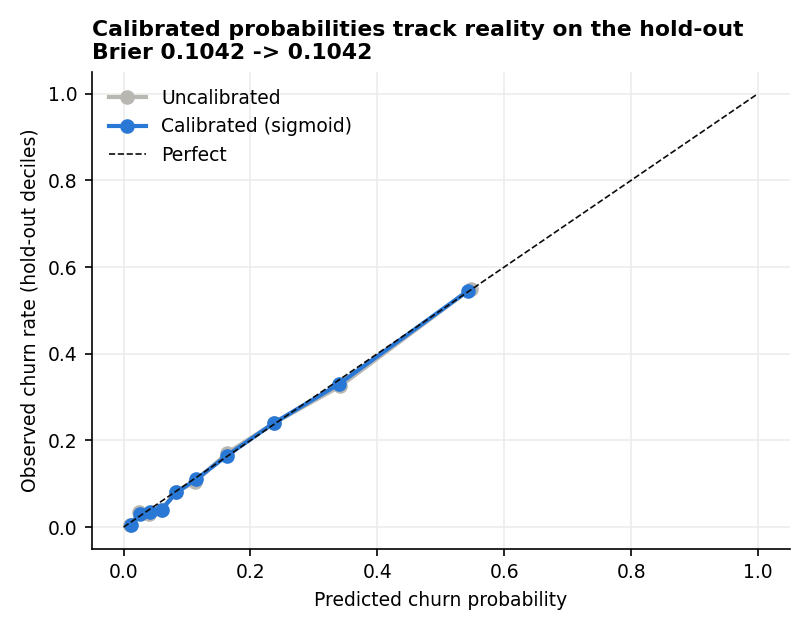

In [9]:
display(Image('../outputs/figures/11_calibration.png'))

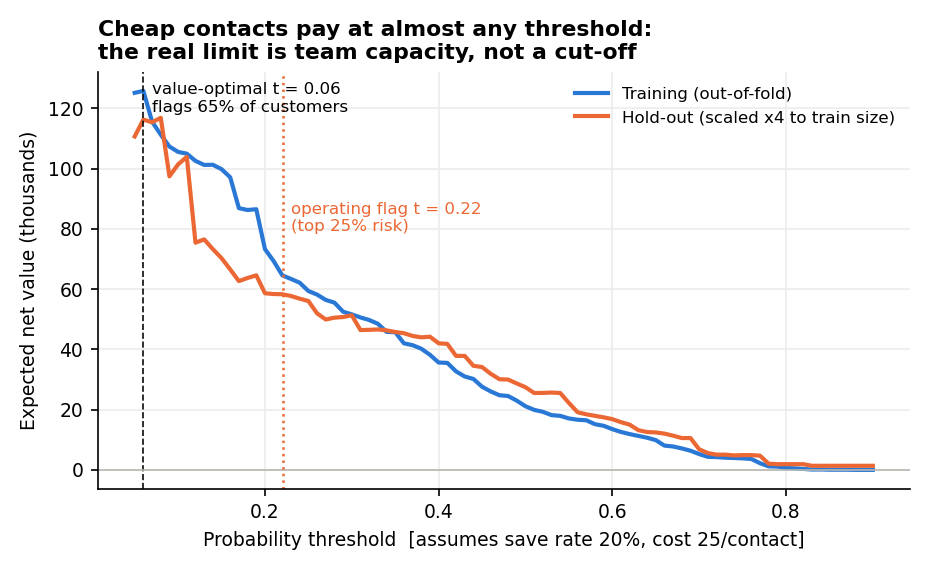

In [10]:
display(Image('../outputs/figures/12_threshold_cost_curve.png'))

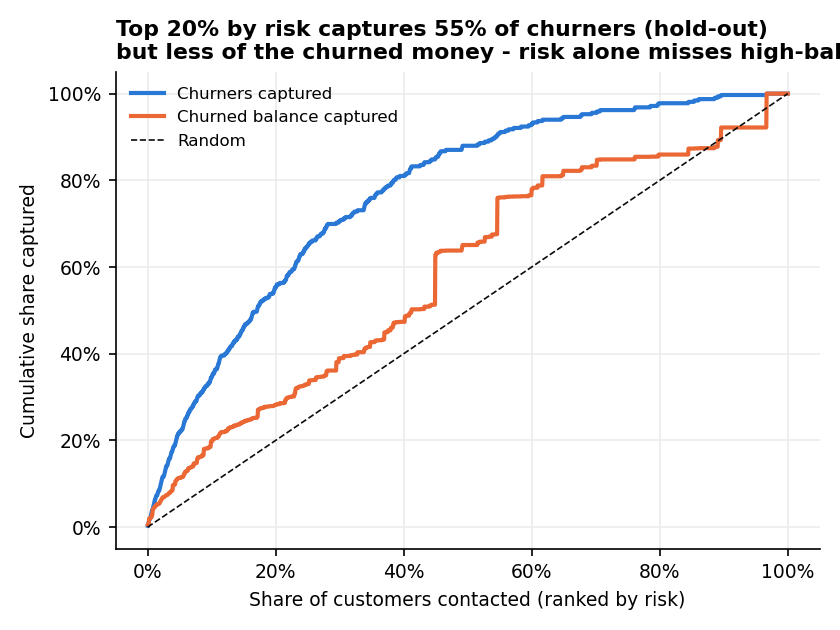

In [11]:
display(Image('../outputs/figures/13_gain_curve.png'))

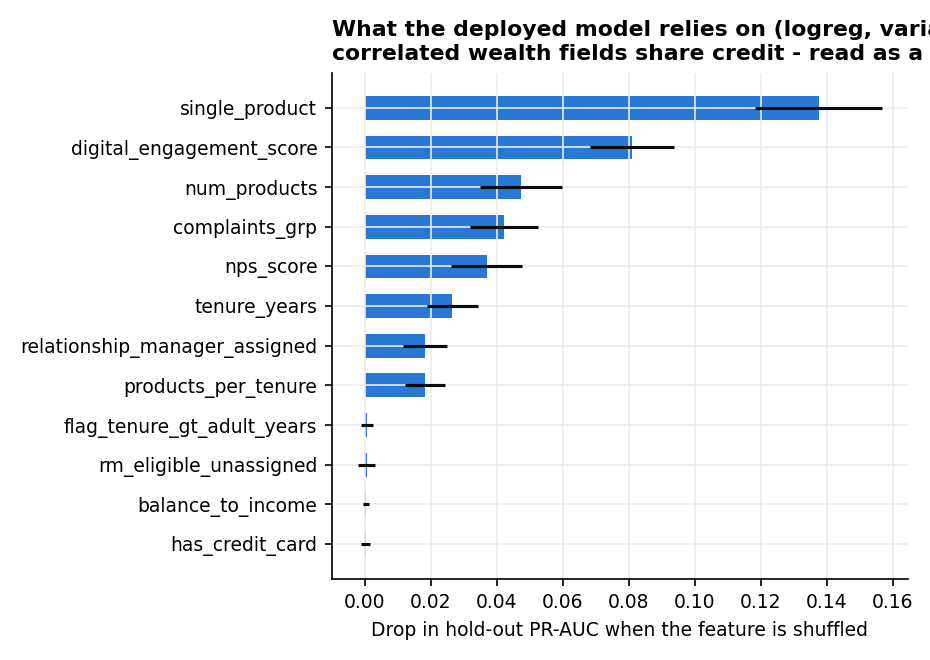

In [12]:
display(Image('../outputs/figures/14_permutation_importance.png'))

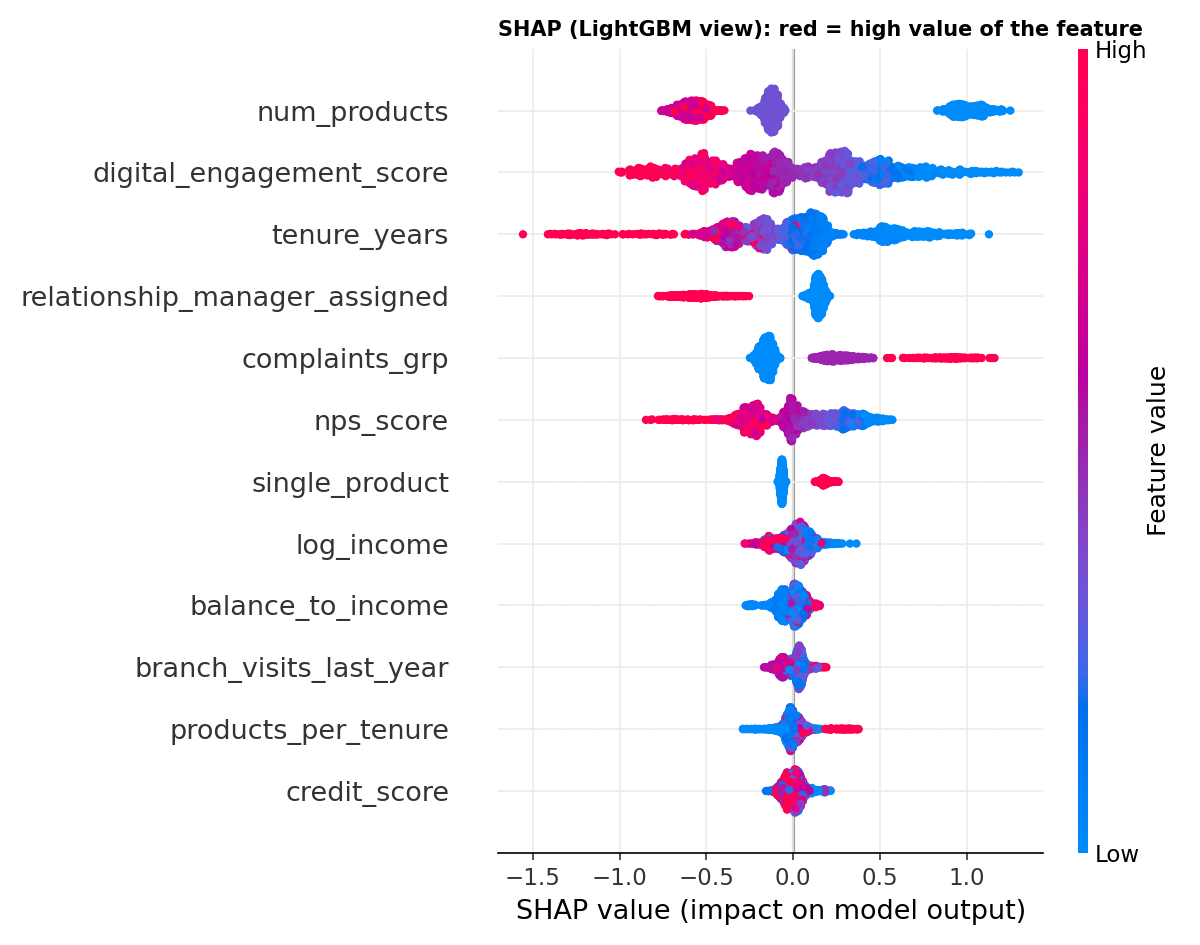

In [13]:
display(Image('../outputs/figures/15_shap_summary.png'))

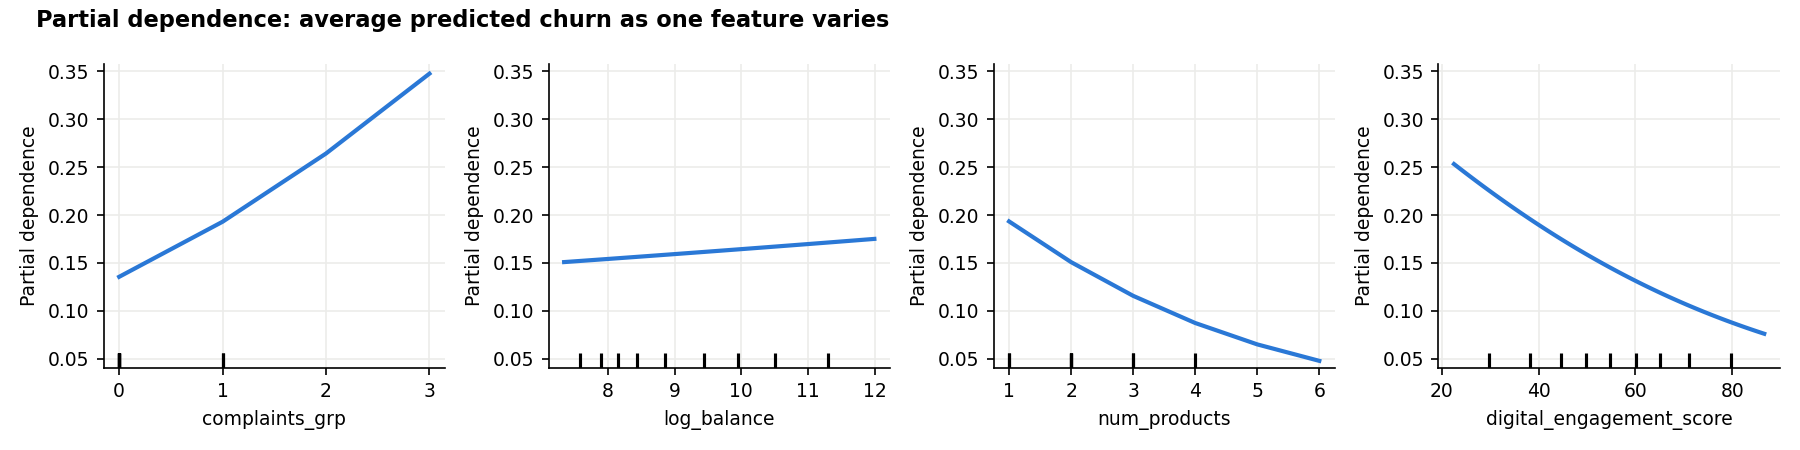

In [14]:
display(Image('../outputs/figures/16_partial_dependence.png'))

## Unseen-data demonstration (train-split model, labels removed, dirty file)

In [15]:
import demo_unseen
demo_unseen.main()

clean_unlabelled {'rows_in': 2000, 'rows_scored': 2000, 'roc_auc': 0.8206462912294417, 'top_decile_hit_rate': 0.545, 'base_rate': 0.158, 'top_decile_lift': 3.449367088607595}


dirty_unlabelled {'rows_in': 2001, 'rows_scored': 2000, 'roc_auc': 0.8207646802369282, 'top_decile_hit_rate': 0.545, 'base_rate': 0.158, 'top_decile_lift': 3.449367088607595}
[PASS] all 2,000 customers scored from dirty file
[PASS] model never trained on these customers
[PASS] demo AUC within 0.02 of reported hold-out AUC
identical scores clean vs dirty: 0.9985
